# Logistic CDF fit — SHS 2023 household income

Load the 2023 Survey of Household Spending (SHS) PUMF, group households by total income, compute weighted population shares, and define a logistic CDF function for income.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SHS_ROOT = Path(r"C:\Users\thoma\Dropbox\SHS")
RY2023_DIR = SHS_ROOT / "RY2023"
DATA_FILE = RY2023_DIR / "Data" / "TXT" / "PUMF_SHS_2023.txt"
CACHE_DIR = SHS_ROOT / "cache"
OUTPUT_DIR = SHS_ROOT / "outputs"
RAW_CACHE_FILE = CACHE_DIR / "shs_2023_notebook_minimal"
PROCESSED_CACHE_FILE = CACHE_DIR / "shs_2023_notebook_processed"

# Column positions from pumf_SHS_2023.dct (1-indexed, inclusive)
COLSPECS = [
    ("caseid", 1, 6, str),
    ("weight", 7, 24, float),
    ("hhtotinc", 66, 76, float),
    ("total_consumption", 3664, 3674, float),  # TC001
    ("total_expenditure", 3697, 3707, float),  # TE001
]
MISSING_NUMERIC = 99_999_999.96

INCOME_BINS = [0, 45_000, 85_000, np.inf]
INCOME_LABELS = ["$0–$45k", "$45k–$85k", "Above $85k"]

# Set True to rebuild the minimal-column cache from the full fixed-width PUMF.
# Leave False to load the compressed cache (or raw PUMF if the cache is missing).
REBUILD_RAW_CACHE = False


## Data: raw PUMF or compressed cache

The notebook only needs a small subset of SHS columns (`caseid`, `weight`, `hhtotinc`, `total_consumption`, `total_expenditure`). Set `REBUILD_RAW_CACHE = True` once to build a minimal cache under `SHS/cache/` from the full fixed-width file; otherwise the cache is loaded before processing.

Cache format: **Parquet (zstd)** if `pyarrow` is installed, otherwise **gzip pickle**.

In [4]:
def load_shs_pumf(path: Path) -> pd.DataFrame:
    """Read household income, expenditure, consumption, and diary weight from the SHS 2023 PUMF."""
    usecols = [c[0] for c in COLSPECS]
    colspecs = [(c[1] - 1, c[2]) for c in COLSPECS]
    dtypes = {c[0]: c[3] for c in COLSPECS}

    shs_df = pd.read_fwf(
        path,
        colspecs=colspecs,
        names=usecols,
        dtype=dtypes,
        encoding="latin-1",
    )

    numeric_cols = ("weight", "hhtotinc", "total_consumption", "total_expenditure")
    for col in numeric_cols:
        shs_df.loc[shs_df[col] >= MISSING_NUMERIC, col] = np.nan

    shs_df = shs_df.dropna(subset=["weight", "hhtotinc"])
    shs_df = shs_df[(shs_df["weight"] > 0) & (shs_df["hhtotinc"] >= 0)]
    return shs_df.reset_index(drop=True)


def _parquet_engine_available() -> bool:
    try:
        import pyarrow  # noqa: F401
        return True
    except ImportError:
        try:
            import fastparquet  # noqa: F401
            return True
        except ImportError:
            return False


def _cache_paths(path_base: Path) -> tuple:
    """Return (parquet_path, pickle_path) for a cache file stem."""
    path_base = Path(path_base)
    if path_base.suffix == ".parquet":
        path_base = path_base.with_suffix("")
    return path_base.with_suffix(".parquet"), Path(str(path_base) + ".pkl.gz")


def save_compressed_dataframe(df: pd.DataFrame, path_base: Path) -> Path:
    """Save using zstd Parquet when available, else gzip pickle."""
    parquet_path, pickle_path = _cache_paths(path_base)
    parquet_path.parent.mkdir(parents=True, exist_ok=True)

    if _parquet_engine_available():
        df.to_parquet(parquet_path, compression="zstd", index=False)
        return parquet_path

    df.to_pickle(pickle_path, compression="gzip")
    return pickle_path


def load_compressed_dataframe(path_base: Path) -> pd.DataFrame:
    """Load from Parquet or gzip pickle cache."""
    parquet_path, pickle_path = _cache_paths(path_base)

    if pickle_path.exists():
        return pd.read_pickle(pickle_path)
    if parquet_path.exists():
        if not _parquet_engine_available():
            raise ImportError(
                f"Found {parquet_path} but pyarrow is not installed. "
                "Set REBUILD_RAW_CACHE=True to recreate the cache as gzip pickle, "
                "or install pyarrow: pip install pyarrow"
            )
        return pd.read_parquet(parquet_path)

    raise FileNotFoundError(
        f"No cache file found at {parquet_path} or {pickle_path}"
    )


def build_minimal_notebook_cache(raw_path: Path, cache_path: Path) -> pd.DataFrame:
    """Create a compressed cache with only the notebook base columns."""
    df = load_shs_pumf(raw_path)
    out_path = save_compressed_dataframe(df, cache_path)
    print(f"Cache format: {out_path.suffix} ({'Parquet/zstd' if out_path.suffix == '.parquet' else 'gzip pickle'})")
    return df


def load_notebook_data(
    raw_path: Path,
    cache_path: Path,
    rebuild_cache: bool = False,
) -> pd.DataFrame:
    """Load notebook base data from cache, or from raw PUMF if requested/missing."""
    cache_path = Path(cache_path)
    raw_path = Path(raw_path)
    parquet_path, pickle_path = _cache_paths(cache_path)

    if rebuild_cache:
        if not raw_path.exists():
            raise FileNotFoundError(f"SHS PUMF not found: {raw_path}")
        df = build_minimal_notebook_cache(raw_path, cache_path)
        out_path = parquet_path if parquet_path.exists() else pickle_path
        nbytes = out_path.stat().st_size
        print(f"Rebuilt minimal cache ({nbytes:,} bytes): {out_path}")
        return df

    if parquet_path.exists() or pickle_path.exists():
        df = load_compressed_dataframe(cache_path)
        out_path = parquet_path if parquet_path.exists() else pickle_path
        print(f"Loaded {len(df):,} households from cache: {out_path}")
        return df

    if not raw_path.exists():
        raise FileNotFoundError(
            f"Neither cache nor raw PUMF found. Tried: {parquet_path}, {pickle_path}; raw: {raw_path}"
        )

    print("Cache not found; loading from raw PUMF...")
    df = load_shs_pumf(raw_path)
    print(f"Loaded {len(df):,} households from raw PUMF")
    return df


if not _parquet_engine_available():
    print(
        "pyarrow/fastparquet not installed; cache files will use gzip pickle. "
        "Install with: pip install pyarrow"
    )

shs_df = load_notebook_data(
    DATA_FILE,
    RAW_CACHE_FILE,
    rebuild_cache=REBUILD_RAW_CACHE,
)
shs_df.head()

Loaded 5,485 households from cache: C:\Users\thoma\Dropbox\SHS\cache\shs_2023_notebook_minimal.parquet


,caseid,weight,hhtotinc,total_consumption,total_expenditure
0,000010,789.2725,87725.0,71511.70,86731.25
1,000020,4449.7826,25294.0,97747.98,99623.98
2,000030,1103.6436,3055.0,51921.99,51921.99
3,000040,163.0420,46584.0,26851.76,28329.03
4,000050,221.2560,91463.0,36423.32,47758.32


In [5]:
shs_df["income_group"] = pd.cut(
    shs_df["hhtotinc"],
    bins=INCOME_BINS,
    labels=INCOME_LABELS,
    right=False,
    include_lowest=True,
)

total_weight = shs_df["weight"].sum()
group_weights = shs_df.groupby("income_group", observed=True)["weight"].sum()
group_shares = (group_weights / total_weight).rename("share")

share_table = pd.DataFrame({
    "weighted_households": group_weights,
    "share": group_shares,
})
share_table

,weighted_households,share
income_group,,
$0–$45k,3.324719e+06,0.212449
$45k–$85k,4.105131e+06,0.262318
Above $85k,8.219616e+06,0.525233


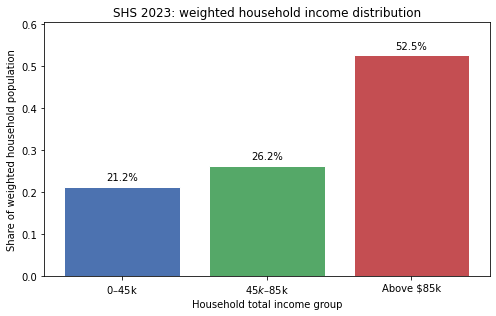

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    share_table.index.astype(str),
    share_table["share"],
    color=["#4c72b0", "#55a868", "#c44e52"],
    edgecolor="white",
)

ax.set_ylabel("Share of weighted household population")
ax.set_xlabel("Household total income group")
ax.set_title("SHS 2023: weighted household income distribution")
ax.set_ylim(0, max(share_table["share"]) * 1.15)

for i, share in enumerate(share_table["share"]):
    ax.text(i, share + 0.01, f"{share:.1%}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [7]:
def logistic_cdf(income, location: float, scale: float, max_level: float = 1.0) -> np.ndarray:
    """
    Logistic distribution CDF evaluated at income.

    Parameters
    ----------
    income : array-like
        Household income value(s) at which to evaluate the CDF.
    location : float
        Location parameter (mu) of the logistic distribution.
    scale : float
        Scale parameter (s) of the logistic distribution; must be positive.

    Returns
    -------
    np.ndarray
        CDF value(s): F(income) = 1 / (1 + exp(-(income - location) / scale)).
    """
    if scale <= 0:
        raise ValueError("scale must be positive")

    x = np.asarray(income, dtype=float)
    z = (x - location) / scale
    lcdfval = 1.0 / (1.0 + np.exp(-z)) * max_level
    return lcdfval

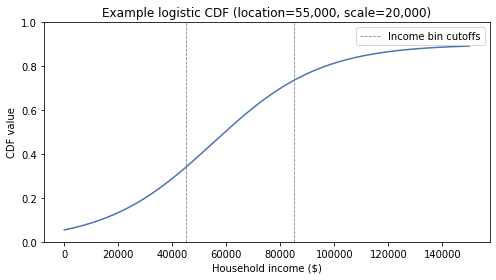

In [8]:
# Example: evaluate the logistic CDF over a range of incomes
example_incomes = np.linspace(0, 150_000, 200)
example_cdf = logistic_cdf(example_incomes, location=55_000, scale=20_000, max_level = 0.9)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(example_incomes, example_cdf, color="#4c72b0")
ax.axvline(45_000, color="gray", linestyle="--", linewidth=0.8, label="Income bin cutoffs")
ax.axvline(85_000, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Household income ($)")
ax.set_ylabel("CDF value")
ax.set_title("Example logistic CDF (location=55,000, scale=20,000)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
def logistic_cdf_group_means(
    location: float,
    scale: float,
    max_level: float = 1.0,
    data=shs_df,
    income_col: str = "hhtotinc",
    weight_col: str = "weight",
    group_col: str = "income_group",
    group_order = None,
) -> np.ndarray:
    """
    Evaluate logistic_cdf at each observation's income, then return
    survey-weighted mean CDF values by income group.

    Returns
    -------
    np.ndarray
        Weighted mean CDF in each income group, ordered by group_order
        (default: INCOME_LABELS).
    """
    if data is None:
        data = shs_df
    if group_order is None:
        group_order = INCOME_LABELS

    cdf_values = logistic_cdf(
        data[income_col],
        location=location,
        scale=scale,
        max_level=max_level,
    )

    weighted_cdf = cdf_values * data[weight_col].to_numpy()
    grouped = data.assign(_weighted_cdf=weighted_cdf).groupby(group_col, observed=True)

    numer = grouped["_weighted_cdf"].sum()
    denom = grouped[weight_col].sum()
    group_means = (numer / denom).reindex(group_order)

    return group_means.to_numpy()


# Example
logistic_cdf_group_means(data= shs_df, location=55_000, scale=20_000, max_level=0.9)

array([0.19772398, 0.53854653, 0.86624565])

In [10]:
class ScaleParameters:
    """
    Element-wise parameter scaler with a fixed reference vector.

    Create an instance with a reference array, then use scale() and
    unscale() to move between original and unit-scaled parameter values.
    When parameters equal the reference, scale() returns ones.
    """

    def __init__(self, reference):
        self.reference = np.asarray(reference, dtype=float)
        if self.reference.ndim != 1:
            raise ValueError("reference must be a 1D array")
        if np.any(self.reference == 0):
            raise ValueError("reference values must be non-zero")

    def _validate_shape(self, values):
        values = np.asarray(values, dtype=float)
        if values.shape != self.reference.shape:
            raise ValueError("parameters must have the same shape as reference")
        return values

    def scale(self, parameters):
        """Return parameters / reference."""
        return self._validate_shape(parameters) / self.reference

    def unscale(self, scaled_parameters):
        """Return scaled_parameters * reference."""
        return self._validate_shape(scaled_parameters) * self.reference


# Example: create a scaler for logistic CDF parameters
logistic_cdf_scaler = ScaleParameters([55_000, 20_000, 0.9])

scaled_parameters = logistic_cdf_scaler.scale([55_000, 20_000, 0.9])
restored_parameters = logistic_cdf_scaler.unscale(scaled_parameters)

scaled_parameters, restored_parameters

(array([1., 1., 1.]), array([5.5e+04, 2.0e+04, 9.0e-01]))

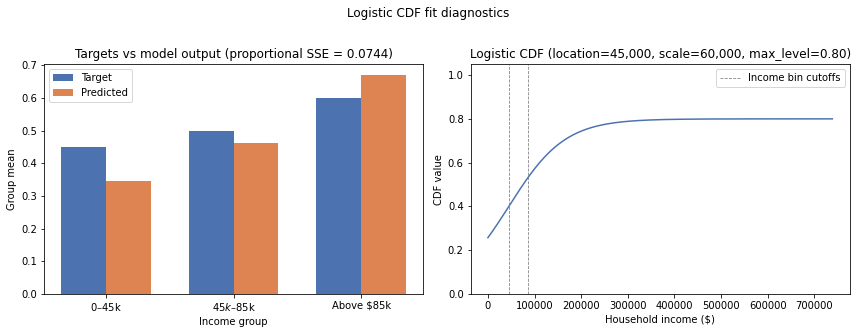

0.07438077662871936

In [11]:
def logistic_cdf_sse(
    targets,
    parameters,
    data=shs_df,
    plot: bool = False,
    income_max=None,
) -> float:
    """
    Compare logistic_cdf_group_means output to a target vector via sum of
    squared proportional errors.

    Parameters
    ----------
    targets : array-like
        Target values for each income group (same length/order as INCOME_LABELS).
    parameters : array-like
        Logistic CDF parameters: [location, scale, max_level].
    data : pd.DataFrame, optional
        Household data passed through to logistic_cdf_group_means.
    plot : bool, optional
        If True, show a two-panel figure comparing targets to predictions and
        the logistic CDF curve implied by the parameters.
    income_max : float, optional
        Upper income bound for the CDF curve panel. Defaults to 5% above the
        maximum observed income in data.

    Returns
    -------
    float
        Sum of squared proportional errors:
        sum(((predicted - target) / target)^2).
    """
    targets = np.asarray(targets, dtype=float)
    location, scale, max_level = parameters

    predicted = logistic_cdf_group_means(
        location=location,
        scale=scale,
        max_level=max_level,
        data=data,
    )

    proportional_deviations = (predicted - targets) / targets
    sse = float(np.sum(proportional_deviations ** 2))

    if plot:
        if income_max is None:
            income_max = float(data["hhtotinc"].max() * 1.05)

        income_grid = np.linspace(0, income_max, 300)
        curve = logistic_cdf(income_grid, location, scale, max_level)

        x = np.arange(len(targets))
        width = 0.35
        group_labels = [str(label) for label in INCOME_LABELS]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

        ax = axes[0]
        ax.bar(x - width / 2, targets, width, label="Target", color="#4c72b0")
        ax.bar(x + width / 2, predicted, width, label="Predicted", color="#dd8452")
        ax.set_xticks(x)
        ax.set_xticklabels(group_labels)
        ax.set_ylabel("Group mean")
        ax.set_xlabel("Income group")
        ax.set_title(f"Targets vs model output (proportional SSE = {sse:.4f})")
        ax.legend()

        ax = axes[1]
        ax.plot(income_grid, curve, color="#4c72b0")
        ax.axvline(45_000, color="gray", linestyle="--", linewidth=0.8, label="Income bin cutoffs")
        ax.axvline(85_000, color="gray", linestyle="--", linewidth=0.8)
        ax.set_xlabel("Household income ($)")
        ax.set_ylabel("CDF value")
        ax.set_title(
            f"Logistic CDF (location={location:,.0f}, scale={scale:,.0f}, max_level={max_level:.2f})"
        )
        ax.set_ylim(0, max(1.0, max_level) * 1.05)
        ax.legend()

        fig.suptitle("Logistic CDF fit diagnostics", y=1.02)
        plt.tight_layout()
        plt.show()

    return sse


# Example: compare model group means to target values
data_targets = np.array([0.45, 0.5, 0.6])
example_parameters = [45_000, 60_000, 0.8]

logistic_cdf_sse(data_targets, example_parameters, plot=True)

Optimisation successful: True
Optimal parameters [location, scale, max_level]:
  location   = 4,500.00
  scale      = 170,676.25
  max_level  = 0.8460
Minimum proportional SSE = 0.000122


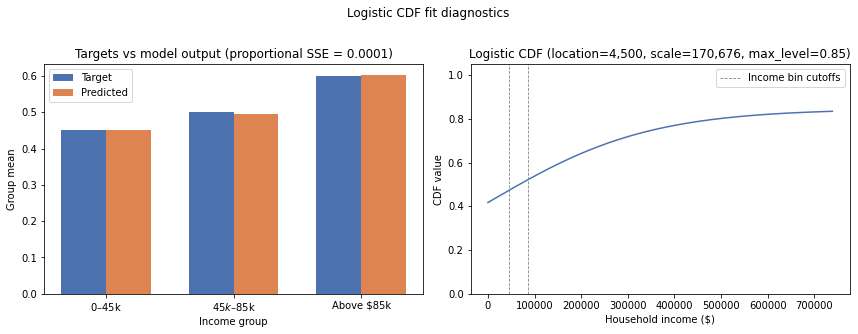

0.00012182987870183702

In [12]:
from scipy.optimize import minimize


def fit_logistic_cdf_targets(
    data_targets,
    data=shs_df,
    x0=None,
    bounds=None,
    parameter_scaler=None,
):
    """
    Minimise logistic_cdf_sse (sum of squared proportional errors) over
    [location, scale, max_level].

    Optimisation runs in the scaled parameter space defined by
    parameter_scaler, then returns parameters on the original scale.

    Returns
    -------
    optimal_parameters : np.ndarray
        Fitted [location, scale, max_level] on the original scale.
    result : scipy.optimize.OptimizeResult
        Full minimisation result in scaled parameter space.
    """
    if parameter_scaler is None:
        raise ValueError("parameter_scaler is required")

    data_targets = np.asarray(data_targets, dtype=float)

    if x0 is None:
        x0 = parameter_scaler.reference.copy()

    scaled_x0 = parameter_scaler.scale(x0)

    if bounds is None:
        bounds = [(0.1, 3.0), (0.1, 3.0), (0.1, 3.0)]

    def objective(scaled_parameters):
        parameters = parameter_scaler.unscale(scaled_parameters)
        return logistic_cdf_sse(data_targets, parameters, data=data, plot=False)

    result = minimize(
        objective,
        x0=scaled_x0,
        bounds=bounds,
        method="L-BFGS-B",
    )

    optimal_parameters = parameter_scaler.unscale(result.x)
    return optimal_parameters, result


# Scaler tied to the example starting values
example_parameter_scaler = ScaleParameters(example_parameters)

optimal_parameters, opt_result = fit_logistic_cdf_targets(
    data_targets,
    x0=example_parameters,
    parameter_scaler=example_parameter_scaler,
)

print("Optimisation successful:", opt_result.success)
print("Optimal parameters [location, scale, max_level]:")
print(f"  location   = {optimal_parameters[0]:,.2f}")
print(f"  scale      = {optimal_parameters[1]:,.2f}")
print(f"  max_level  = {optimal_parameters[2]:.4f}")
print(f"Minimum proportional SSE = {opt_result.fun:.6f}")

final_sse = logistic_cdf_sse(data_targets, optimal_parameters, plot=True)
final_sse

In [13]:
location, scale, max_level = optimal_parameters

shs_df["imputed_CC_prop"] = logistic_cdf(
    shs_df["hhtotinc"],
    location=location,
    scale=scale,
    max_level=max_level,
)

# Sanity check: weighted group means of imputed_CC_prop match model predictions
predicted_group_means = logistic_cdf_group_means(
    location=location,
    scale=scale,
    max_level=max_level,
)

print("Weighted mean imputed_CC_prop by income group:")
for label, value in zip(INCOME_LABELS, predicted_group_means):
    print(f"  {label}: {value:.4f}")

shs_df["CCspend"] = shs_df["total_consumption"] * shs_df["imputed_CC_prop"]
shs_df["CCspend_exp"] = shs_df["total_expenditure"] * shs_df["imputed_CC_prop"]

shs_df[
    [
        "caseid",
        "hhtotinc",
        "total_consumption",
        "total_expenditure",
        "income_group",
        "weight",
        "imputed_CC_prop",
        "CCspend",
        "CCspend_exp",
    ]
].head(10)

Weighted mean imputed_CC_prop by income group:
  $0–$45k: 0.4522
  $45k–$85k: 0.4955
  Above $85k: 0.6024


,caseid,hhtotinc,total_consumption,total_expenditure,income_group,weight,imputed_CC_prop,CCspend,CCspend_exp
0,000010,87725.0,71511.70,86731.25,Above $85k,789.2725,0.524105,37479.641906,45456.284665
1,000020,25294.0,97747.98,99623.98,$0–$45k,4449.7826,0.448710,43860.481848,44702.261534
2,000030,3055.0,51921.99,51921.99,$0–$45k,1103.6436,0.421185,21868.762266,21868.762266
3,000040,46584.0,26851.76,28329.03,$45k–$85k,163.0420,0.474860,12750.823027,13452.319254
4,000050,91463.0,36423.32,47758.32,Above $85k,221.2560,0.528460,19248.285821,25238.385564
5,000060,81954.0,201959.37,224704.37,$45k–$85k,2914.8630,0.517336,104480.884119,116247.694985
6,000070,106958.0,54267.19,91153.08,Above $85k,6148.7152,0.546253,29643.606212,49792.628079
7,000080,47019.0,42806.12,46434.12,$45k–$85k,6022.2028,0.475391,20349.630630,22074.348028
8,000090,122804.0,129035.44,151635.16,Above $85k,176.0849,0.563968,72771.805158,85517.314613
9,000100,103347.0,45230.54,77950.54,Above $85k,1174.0320,0.542146,24521.554267,42260.569888


## Log CCspend and CCspend_exp vs log income

Weighted OLS, local (kernel) regression, and upper-tail Pareto / Lorenz analysis for `CCspend` (total consumption × imputed CC share) and `CCspend_exp` (total expenditure × imputed CC share).

In [14]:
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess

CC_MEASURES = ["CCspend", "CCspend_exp"]


def weighted_ols(y, x, w):
    """Weighted least squares with intercept."""
    X = sm.add_constant(pd.Series(x, name="log_income"))
    return sm.WLS(y, X, weights=w).fit()


def weighted_local_linear(x, y, w, x_grid, bandwidth=None):
    """Nadaraya-Watson-style weighted local linear smoother."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)
    w = w / w.sum()

    if bandwidth is None:
        order = np.argsort(x)
        x_s, w_s = x[order], w[order]
        cum_w = np.cumsum(w_s)
        q25 = x_s[np.searchsorted(cum_w, 0.25)]
        q75 = x_s[np.searchsorted(cum_w, 0.75)]
        bandwidth = max(0.15, 0.05 * (q75 - q25))

    y_hat = np.empty_like(x_grid, dtype=float)
    for i, x0 in enumerate(x_grid):
        dist = (x - x0) / bandwidth
        kw = w * np.exp(-0.5 * dist ** 2)
        if kw.sum() <= 0:
            y_hat[i] = np.nan
            continue
        W = np.diag(kw)
        Xloc = np.column_stack([np.ones_like(x), x - x0])
        beta = np.linalg.lstsq(Xloc.T @ W @ Xloc, Xloc.T @ W @ y, rcond=None)[0]
        y_hat[i] = beta[0]
    return y_hat


def weighted_lorenz_curve(values, weights):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v)
    v, w = v[order], w[order]
    w = w / w.sum()
    cum_w = np.cumsum(w)
    cum_xw = np.cumsum(v * w)
    return cum_w, cum_xw / cum_xw[-1]


def paretocoeff(top_frac, top_share):
    if not (0 < top_frac < 1) or not (0 < top_share < 1):
        return np.nan
    return np.log(top_frac) / (np.log(top_frac) - np.log(top_share))


def weighted_top_share(values, weights, top_frac):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(-v)
    v, w = v[order], w[order]
    total = float(np.dot(w, v))
    if total <= 0:
        return np.nan
    target = top_frac * float(w.sum())
    j = int(np.searchsorted(np.cumsum(w), target, side="left"))
    j = min(max(j, 0), len(w) - 1)
    return float(np.dot(w[: j + 1], v[: j + 1])) / total


def estimate_pareto_alpha(values, weights, top_fracs=(0.10, 0.05, 0.01)):
    alphas = []
    for q in top_fracs:
        share = weighted_top_share(values, weights, q)
        a = paretocoeff(q, share)
        if np.isfinite(a) and a > 1:
            alphas.append(a)
    return float(np.mean(alphas)) if alphas else np.nan


def pareto_lorenz(p, alpha):
    return 1.0 - (1.0 - p) ** (1.0 - 1.0 / alpha)


def lorenz_coefficient(alpha):
    if alpha <= 1:
        return np.nan
    return alpha / (alpha - 1.0)


def weighted_quantile(values, weights, probs):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    probs_arr = np.atleast_1d(probs).astype(float)
    order = np.argsort(v)
    v, w = v[order], w[order]
    w = w / w.sum()
    cum_w = np.cumsum(w)
    out = np.empty_like(probs_arr, dtype=float)
    for i, p in enumerate(probs_arr):
        j = int(np.searchsorted(cum_w, p, side="left"))
        j = min(max(j, 0), len(v) - 1)
        out[i] = v[j]
    return out[0] if np.ndim(probs) == 0 else out


def calibrate_pareto_scale(values, weights, alpha):
    w = np.asarray(weights, dtype=float)
    v = np.asarray(values, dtype=float)
    mean_x = float(np.dot(w, v) / w.sum())
    return mean_x * (alpha - 1.0) / alpha


def pareto_quantile(p, alpha, x_min):
    p_arr = np.asarray(p, dtype=float)
    return x_min * (1.0 - p_arr) ** (-1.0 / alpha)


def pareto_quantile_table(alpha, x_min, percentiles, values=None, weights=None, label="spend"):
    probs = np.array(percentiles, dtype=float) / 100.0
    fitted = pareto_quantile(probs, alpha, x_min)
    rows = {
        "percentile": percentiles,
        "population_share_p": probs,
        f"pareto_{label}": fitted,
    }
    if values is not None and weights is not None:
        rows[f"empirical_{label}"] = weighted_quantile(values, weights, probs)
    return pd.DataFrame(rows)


def pareto_conditional_mean(p_low, p_high, alpha, x_min):
    if alpha <= 1:
        return np.nan
    mass = p_high - p_low
    if mass <= 0:
        return np.nan
    term = (1.0 - p_low) ** ((alpha - 1.0) / alpha) - (1.0 - p_high) ** (
        (alpha - 1.0) / alpha
    )
    return (alpha / (alpha - 1.0)) * x_min * term / mass


def weighted_percentile_group_mean(values, weights, p_low, p_high):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v)
    v, w = v[order], w[order]
    w = w / w.sum()
    cum_w = np.cumsum(w)
    cum_w_lag = np.concatenate(([0.0], cum_w[:-1]))
    mask = (cum_w > p_low) & (cum_w_lag < p_high)
    if not mask.any():
        return np.nan
    group_w = w[mask]
    return float(np.dot(group_w, v[mask]) / group_w.sum())


mask = (shs_df["hhtotinc"] > 0)
for measure in CC_MEASURES:
    mask &= shs_df[measure] > 0
analysis_df = shs_df.loc[mask].copy()
analysis_df["log_income"] = np.log(analysis_df["hhtotinc"])
for measure in CC_MEASURES:
    analysis_df[f"log_{measure}"] = np.log(analysis_df[measure])

print(f"{len(analysis_df):,} households with positive income, CCspend, CCspend_exp, and weight")

5,485 households with positive income, CCspend, CCspend_exp, and weight



Weighted OLS: log(CCspend) ~ log(income)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.8124      0.088     43.340      0.000       3.640       3.985
log_income     0.5862      0.008     75.616      0.000       0.571       0.601
  R-squared: 0.5105

Weighted OLS: log(CCspend_exp) ~ log(income)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.1703      0.081     26.667      0.000       2.011       2.330
log_income     0.7542      0.007    105.158      0.000       0.740       0.768
  R-squared: 0.6685


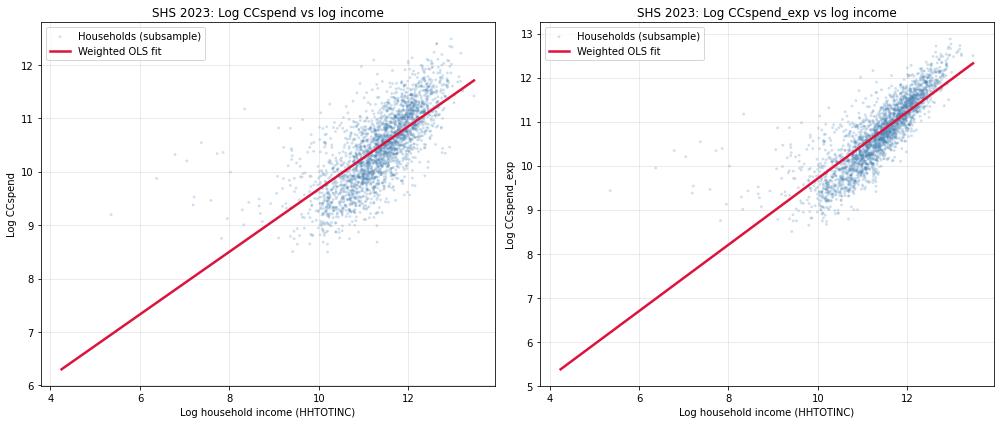

In [15]:
x = analysis_df["log_income"].to_numpy()
w = analysis_df["weight"].to_numpy()
rng = np.random.default_rng(42)
idx = rng.choice(len(analysis_df), size=min(2500, len(analysis_df)), replace=False, p=w / w.sum())

cc_results = {}
fig, axes = plt.subplots(1, len(CC_MEASURES), figsize=(7 * len(CC_MEASURES), 6))
if len(CC_MEASURES) == 1:
    axes = [axes]

for ax, measure in zip(axes, CC_MEASURES):
    y = analysis_df[f"log_{measure}"].to_numpy()
    ols = weighted_ols(y, x, w)
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = ols.params["const"] + ols.params["log_income"] * x_line
    cc_results[measure] = {
        "ols": ols,
        "cons": analysis_df[measure].to_numpy(),
        "x_line": x_line,
        "y_line": y_line,
    }

    print(f"\nWeighted OLS: log({measure}) ~ log(income)")
    print(ols.summary().tables[1])
    print(f"  R-squared: {ols.rsquared:.4f}")

    ax.scatter(x[idx], y[idx], s=8, alpha=0.25, c="steelblue", edgecolors="none", label="Households (subsample)")
    ax.plot(x_line, y_line, color="crimson", lw=2.5, label="Weighted OLS fit")
    ax.set_xlabel("Log household income (HHTOTINC)")
    ax.set_ylabel(f"Log {measure}")
    ax.set_title(f"SHS 2023: Log {measure} vs log income")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

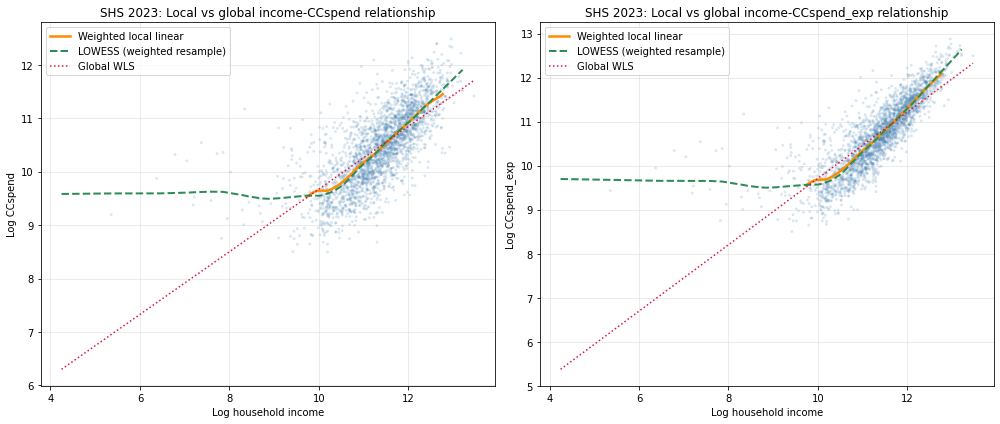

In [16]:
x_grid = np.linspace(np.quantile(x, 0.02), np.quantile(x, 0.98), 150)
n_resample = min(8000, len(analysis_df))
idx_r = rng.choice(len(analysis_df), size=n_resample, replace=True, p=w / w.sum())

fig, axes = plt.subplots(1, len(CC_MEASURES), figsize=(7 * len(CC_MEASURES), 6))
if len(CC_MEASURES) == 1:
    axes = [axes]

for ax, measure in zip(axes, CC_MEASURES):
    y = analysis_df[f"log_{measure}"].to_numpy()
    y_local = weighted_local_linear(x, y, w, x_grid)
    lowess_fit = lowess(y[idx_r], x[idx_r], frac=0.25, return_sorted=True)
    x_line = cc_results[measure]["x_line"]
    y_line = cc_results[measure]["y_line"]

    ax.scatter(x[idx], y[idx], s=8, alpha=0.2, c="steelblue", edgecolors="none")
    ax.plot(x_grid, y_local, color="darkorange", lw=2.5, label="Weighted local linear")
    ax.plot(lowess_fit[:, 0], lowess_fit[:, 1], color="seagreen", lw=2, ls="--", label="LOWESS (weighted resample)")
    ax.plot(x_line, y_line, color="crimson", lw=1.5, ls=":", label="Global WLS")
    ax.set_xlabel("Log household income")
    ax.set_ylabel(f"Log {measure}")
    ax.set_title(f"SHS 2023: Local vs global income-{measure} relationship")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Upper-tail CCspend (weighted):
  Top 10% share : 0.263
  Top  5% share : 0.157
  Top  1% share : 0.044
  Pareto alpha  : 2.711
  Lorenz coeff (eta = alpha/(alpha-1)): 1.584

Upper-tail CCspend_exp (weighted):
  Top 10% share : 0.285
  Top  5% share : 0.171
  Top  1% share : 0.049
  Pareto alpha  : 2.511
  Lorenz coeff (eta = alpha/(alpha-1)): 1.662


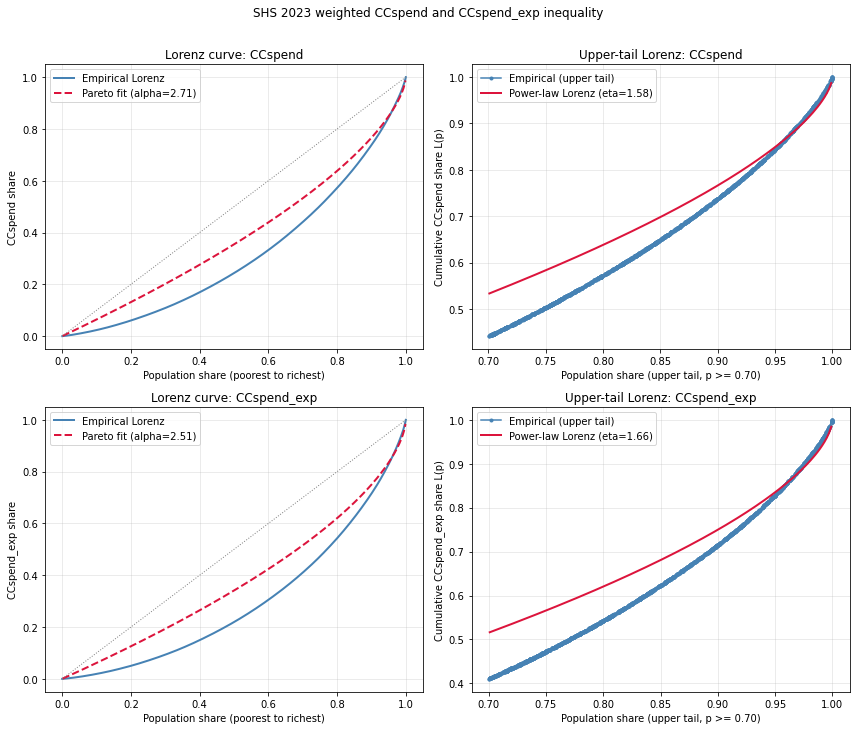

,measure,n_households,ols_intercept,ols_slope_log_income,ols_r_squared,top10_share,top5_share,top1_share,pareto_alpha,lorenz_coefficient_eta
0,CCspend,5485,3.812443,0.586211,0.510480,0.262947,0.156789,0.043524,2.711375,1.584325
1,CCspend_exp,5485,2.170300,0.754235,0.668526,0.284922,0.171462,0.048865,2.510947,1.661836


In [17]:
summary_rows = []
fig, axes = plt.subplots(len(CC_MEASURES), 2, figsize=(12, 5 * len(CC_MEASURES)))
if len(CC_MEASURES) == 1:
    axes = np.array([axes])

for row, measure in enumerate(CC_MEASURES):
    cons = cc_results[measure]["cons"]
    ols = cc_results[measure]["ols"]

    p_emp, l_emp = weighted_lorenz_curve(cons, w)
    alpha = estimate_pareto_alpha(cons, w)
    eta = lorenz_coefficient(alpha)
    share10 = weighted_top_share(cons, w, 0.10)
    share5 = weighted_top_share(cons, w, 0.05)
    share1 = weighted_top_share(cons, w, 0.01)
    x_min = calibrate_pareto_scale(cons, w, alpha)

    cc_results[measure].update(
        {
            "alpha": alpha,
            "eta": eta,
            "x_min": x_min,
            "share10": share10,
            "share5": share5,
            "share1": share1,
        }
    )

    print(f"\nUpper-tail {measure} (weighted):")
    print(f"  Top 10% share : {share10:.3f}")
    print(f"  Top  5% share : {share5:.3f}")
    print(f"  Top  1% share : {share1:.3f}")
    print(f"  Pareto alpha  : {alpha:.3f}")
    print(f"  Lorenz coeff (eta = alpha/(alpha-1)): {eta:.3f}")

    summary_rows.append(
        {
            "measure": measure,
            "n_households": len(analysis_df),
            "ols_intercept": ols.params["const"],
            "ols_slope_log_income": ols.params["log_income"],
            "ols_r_squared": ols.rsquared,
            "top10_share": share10,
            "top5_share": share5,
            "top1_share": share1,
            "pareto_alpha": alpha,
            "lorenz_coefficient_eta": eta,
        }
    )

    p_fine = np.linspace(0.001, 0.999, 500)
    l_pareto = pareto_lorenz(p_fine, alpha)
    tail_mask = p_emp >= 0.70

    ax = axes[row, 0]
    ax.plot(p_emp, l_emp, color="steelblue", lw=2, label="Empirical Lorenz")
    ax.plot(p_fine, l_pareto, color="crimson", lw=2, ls="--", label=f"Pareto fit (alpha={alpha:.2f})")
    ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1)
    ax.set_xlabel("Population share (poorest to richest)")
    ax.set_ylabel(f"{measure} share")
    ax.set_title(f"Lorenz curve: {measure}")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[row, 1]
    ax.plot(p_emp[tail_mask], l_emp[tail_mask], "o-", color="steelblue", ms=3, label="Empirical (upper tail)")
    p_tail = p_fine[p_fine >= 0.70]
    ax.plot(p_tail, pareto_lorenz(p_tail, alpha), color="crimson", lw=2, label=f"Power-law Lorenz (eta={eta:.2f})")
    ax.set_xlabel("Population share (upper tail, p >= 0.70)")
    ax.set_ylabel(f"Cumulative {measure} share L(p)")
    ax.set_title(f"Upper-tail Lorenz: {measure}")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("SHS 2023 weighted CCspend and CCspend_exp inequality", y=1.01)
plt.tight_layout()
plt.show()

summary = pd.DataFrame(summary_rows)
summary


CCspend: Pareto scale x_min (mean-calibrated): $27,425
CCspend quantiles from fitted Pareto(alpha) vs empirical (weighted):
 percentile  population_share_p pareto_CCspend empirical_CCspend pareto_CCspend_monthly empirical_CCspend_monthly
       90.0               0.900        $64,115           $82,283                 $5,343                    $6,857
       95.0               0.950        $82,791          $104,731                 $6,899                    $8,728
       96.0               0.960        $89,893          $112,544                 $7,491                    $9,379
       97.0               0.970        $99,955          $119,923                 $8,330                    $9,994
       98.0               0.980       $116,078          $128,698                 $9,673                   $10,725
       99.0               0.990       $149,891          $156,037                $12,491                   $13,003
       99.5               0.995       $193,553          $176,229             

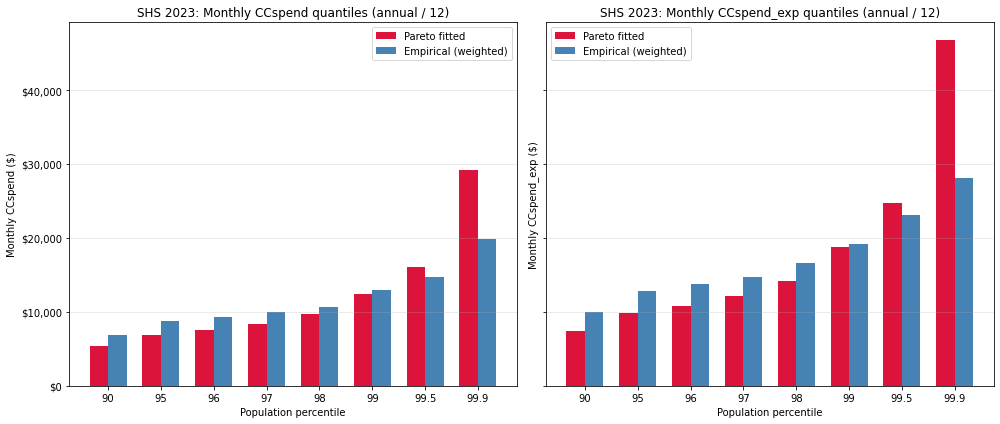

In [18]:
pct_levels = (90, 95, 96, 97, 98, 99, 99.5, 99.9)
pct_labels = [f"{p:g}" for p in pct_levels]
x_pos = np.arange(len(pct_labels))
bar_w = 0.35

fig, axes = plt.subplots(1, len(CC_MEASURES), figsize=(7 * len(CC_MEASURES), 6), sharey=True)
if len(CC_MEASURES) == 1:
    axes = [axes]

for ax, measure in zip(axes, CC_MEASURES):
    cons = cc_results[measure]["cons"]
    alpha = cc_results[measure]["alpha"]
    x_min = cc_results[measure]["x_min"]

    quantile_tbl = pareto_quantile_table(alpha, x_min, pct_levels, cons, w, label=measure)
    quantile_tbl[f"pareto_{measure}_monthly"] = quantile_tbl[f"pareto_{measure}"] / 12.0
    quantile_tbl[f"empirical_{measure}_monthly"] = quantile_tbl[f"empirical_{measure}"] / 12.0
    cc_results[measure]["quantile_tbl"] = quantile_tbl

    print(f"\n{measure}: Pareto scale x_min (mean-calibrated): ${x_min:,.0f}")
    print(f"{measure} quantiles from fitted Pareto(alpha) vs empirical (weighted):")
    print(
        quantile_tbl.to_string(
            index=False,
            formatters={
                f"pareto_{measure}": lambda v, m=measure: f"${v:,.0f}",
                f"empirical_{measure}": lambda v, m=measure: f"${v:,.0f}",
                f"pareto_{measure}_monthly": lambda v, m=measure: f"${v:,.0f}",
                f"empirical_{measure}_monthly": lambda v, m=measure: f"${v:,.0f}",
            },
        )
    )

    ax.bar(x_pos - bar_w / 2, quantile_tbl[f"pareto_{measure}_monthly"], bar_w, label="Pareto fitted", color="crimson")
    ax.bar(x_pos + bar_w / 2, quantile_tbl[f"empirical_{measure}_monthly"], bar_w, label="Empirical (weighted)", color="steelblue")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(pct_labels)
    ax.set_xlabel("Population percentile")
    ax.set_ylabel(f"Monthly {measure} ($)")
    ax.set_title(f"SHS 2023: Monthly {measure} quantiles (annual / 12)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Average CCspend by percentile group (annual and monthly):
 group  p_low  p_high pareto_mean_annual pareto_mean_monthly empirical_mean_annual empirical_mean_monthly
 90-95   0.90    0.95            $71,990              $5,999               $92,467                 $7,706
 95-99   0.95    0.99           $104,591              $8,716              $122,708                $10,226
99-100   0.99    1.00           $237,476             $19,790              $185,523                $15,460

Average CCspend_exp by percentile group (annual and monthly):
 group  p_low  p_high pareto_mean_annual pareto_mean_monthly empirical_mean_annual empirical_mean_monthly
 90-95   0.90    0.95           $101,801              $8,483              $135,459                $11,288
 95-99   0.95    0.99           $152,523             $12,710              $183,319                $15,277
99-100   0.99    1.00           $373,394             $31,116              $289,865                $24,155


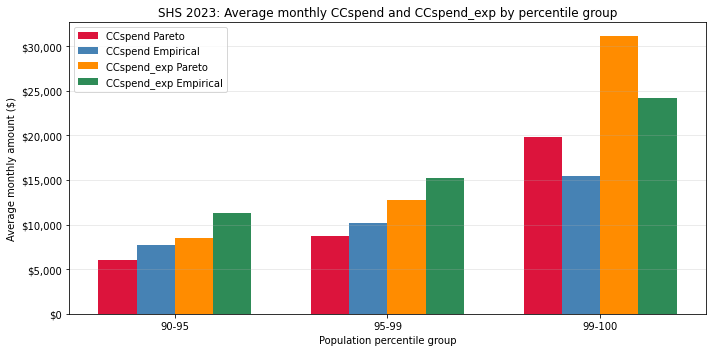

In [19]:
group_defs = (
    ("90-95", 0.90, 0.95),
    ("95-99", 0.95, 0.99),
    ("99-100", 0.99, 1.00),
)

for measure in CC_MEASURES:
    cons = cc_results[measure]["cons"]
    alpha = cc_results[measure]["alpha"]
    x_min = cc_results[measure]["x_min"]

    group_rows = []
    for label, p_lo, p_hi in group_defs:
        annual_pareto = pareto_conditional_mean(p_lo, p_hi, alpha, x_min)
        annual_emp = weighted_percentile_group_mean(cons, w, p_lo, p_hi)
        group_rows.append(
            {
                "group": label,
                "p_low": p_lo,
                "p_high": p_hi,
                "pareto_mean_annual": annual_pareto,
                "pareto_mean_monthly": annual_pareto / 12.0,
                "empirical_mean_annual": annual_emp,
                "empirical_mean_monthly": annual_emp / 12.0,
            }
        )
    group_tbl = pd.DataFrame(group_rows)
    cc_results[measure]["group_tbl"] = group_tbl

    print(f"\nAverage {measure} by percentile group (annual and monthly):")
    print(
        group_tbl.to_string(
            index=False,
            formatters={
                "pareto_mean_annual": lambda v: f"${v:,.0f}",
                "pareto_mean_monthly": lambda v: f"${v:,.0f}",
                "empirical_mean_annual": lambda v: f"${v:,.0f}",
                "empirical_mean_monthly": lambda v: f"${v:,.0f}",
            },
        )
    )

x_pos = np.arange(len(group_defs))
bar_w = 0.18
bar_specs = [
    ("CCspend", "pareto_mean_monthly", "crimson", "CCspend Pareto"),
    ("CCspend", "empirical_mean_monthly", "steelblue", "CCspend Empirical"),
    ("CCspend_exp", "pareto_mean_monthly", "darkorange", "CCspend_exp Pareto"),
    ("CCspend_exp", "empirical_mean_monthly", "seagreen", "CCspend_exp Empirical"),
]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (measure, col, color, label) in enumerate(bar_specs):
    group_tbl = cc_results[measure]["group_tbl"]
    ax.bar(
        x_pos + (i - 1.5) * bar_w,
        group_tbl[col],
        bar_w,
        label=label,
        color=color,
    )

ax.set_xticks(x_pos)
ax.set_xticklabels([label for label, _, _ in group_defs])
ax.set_xlabel("Population percentile group")
ax.set_ylabel("Average monthly amount ($)")
ax.set_title("SHS 2023: Average monthly CCspend and CCspend_exp by percentile group")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Save processed dataset

Write the full `shs_df` (including derived columns) to a compressed Parquet file.

In [20]:
processed_path = save_compressed_dataframe(shs_df, PROCESSED_CACHE_FILE)
processed_bytes = processed_path.stat().st_size

print(f"Saved {len(shs_df):,} households, {len(shs_df.columns)} columns")
print(f"Processed cache: {processed_path} ({processed_bytes:,} bytes)")

parquet_path, pickle_path = _cache_paths(RAW_CACHE_FILE)
if parquet_path.exists():
    print(f"Minimal raw cache: {parquet_path} ({parquet_path.stat().st_size:,} bytes)")
elif pickle_path.exists():
    print(f"Minimal raw cache: {pickle_path} ({pickle_path.stat().st_size:,} bytes)")

Saved 5,485 households, 9 columns
Processed cache: C:\Users\thoma\Dropbox\SHS\cache\shs_2023_notebook_processed.parquet (317,919 bytes)
Minimal raw cache: C:\Users\thoma\Dropbox\SHS\cache\shs_2023_notebook_minimal.parquet (164,913 bytes)


## Export notebook + cache bundle

Create a zip archive containing this notebook and the cache files, then report its size.

In [21]:
import zipfile

CODE_DIR = SHS_ROOT / "code"
NOTEBOOK_FILE = CODE_DIR / "logistic_cc_fit.ipynb"
ZIP_FILE = CACHE_DIR / "shs_2023_notebook_bundle.zip"


def cache_files_for_zip():
    paths = []
    for path_base in (RAW_CACHE_FILE, PROCESSED_CACHE_FILE):
        parquet_path, pickle_path = _cache_paths(path_base)
        if parquet_path.exists():
            paths.append(parquet_path)
        elif pickle_path.exists():
            paths.append(pickle_path)
    return paths


cache_paths = cache_files_for_zip()
input_files = [NOTEBOOK_FILE, *cache_paths]

with zipfile.ZipFile(ZIP_FILE, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(NOTEBOOK_FILE, arcname=f"code/{NOTEBOOK_FILE.name}")
    for cache_path in cache_paths:
        zf.write(cache_path, arcname=f"cache/{cache_path.name}")

zip_bytes = ZIP_FILE.stat().st_size
uncompressed_bytes = sum(path.stat().st_size for path in input_files if path.exists())

print(f"Created: {ZIP_FILE}")
print(f"Contents: notebook + {len(cache_paths)} cache file(s)")
print(f"Zip size: {zip_bytes:,} bytes ({zip_bytes / 1024:.1f} KiB)")
print(f"Uncompressed size: {uncompressed_bytes:,} bytes ({uncompressed_bytes / 1024:.1f} KiB)")
if uncompressed_bytes:
    print(f"Compression ratio: {zip_bytes / uncompressed_bytes:.1%}")

Created: C:\Users\thoma\Dropbox\SHS\cache\shs_2023_notebook_bundle.zip
Contents: notebook + 2 cache file(s)
Zip size: 902,932 bytes (881.8 KiB)
Uncompressed size: 1,130,352 bytes (1103.9 KiB)
Compression ratio: 79.9%
